# Complex postselected QSP dynamics

This notebook implements a genuinely complex approximation to $e^{-iHt}$ using two parity-compatible real QSP polynomials and an explicit coherent selector. The accepted circuit block is approximately $U/4$, so postselection is required. It preserves the separate cosine-filter primitive in the first dynamics notebook.

The fixed task is the three-spin open chain $H=Z_0Z_1+Z_1Z_2+0.7(X_0+X_1+X_2)$, $t=1$, $\hbar=1$, input $|000\rangle$, observable $Z_0$. Frozen phases target $\tau=\alpha t=4.1$. Classical matrices are reference checks; the quantum circuit has actual PREPARE, SELECT, inverse PREPARE, conditioned phase gates and one controlled access call.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import Operator
from scipy.linalg import expm

root = Path.cwd()
if not (root / "src/openquantum/simulation/qsp_evolution.py").exists() and (root.parent / "src/openquantum/simulation/qsp_evolution.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/qsp_evolution.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum import hamiltonian_simulation as hs
    from openquantum.simulation import qsp_evolution as qe
else:
    # Save hamiltonian_simulation.py, lcu.py, qsp.py and qsp_evolution.py beside the notebook.
    sys.path.insert(0, str(root))
    import hamiltonian_simulation as hs
    import qsp_evolution as qe

terms = hs.spin_terms(3)
H = hs.dense_hamiltonian(3)
initial = np.eye(8, dtype=complex)[:, 0]
observable = hs.pauli_matrix("IIZ")
circuit = qe.build_qsp_evolution(terms, time=1)
result = qe.compare_qsp_evolution(circuit, H, initial, observable)
contract = qe.evolution_error_contract()
print(f"Total logical wires: {circuit.num_qubits}; ordinary access calls: {circuit.metadata['uncontrolled_block_encoding_calls']}; controlled access calls: {circuit.metadata['controlled_block_encoding_calls']}")

Total logical wires: 8; ordinary access calls: 14; controlled access calls: 1


## Complex polynomial response

The cosine filter approximates $C(x)=\cos(4.1x)/2$ and the odd sine filter approximates $S(x)=\sin(4.1x)/2$. Preparing a uniform selector, applying a relative $-i$ phase to its sine branch and projecting the selector onto zero yields $[C(x)-iS(x)]/2\approx e^{-i4.1x}/4$.

The implementation shares fourteen ordinary Hermitian-block calls and adds one selector-controlled block call. Every selector-conditioned projector phase is explicit. Both real-part and selector flags, together with all block labels, must be zero to accept.

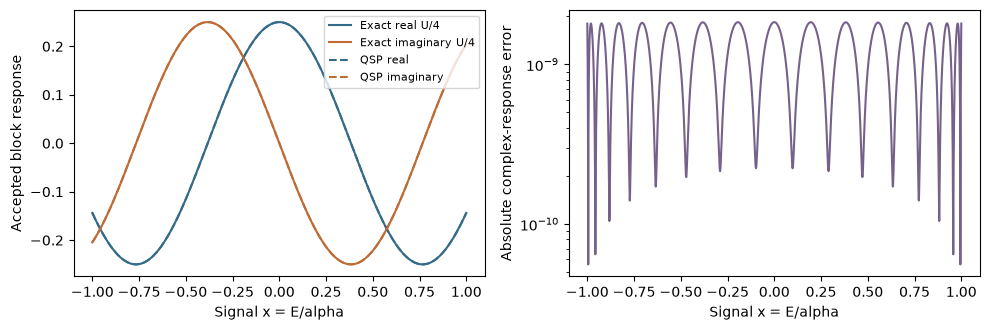

In [2]:
x = np.linspace(-1, 1, 2001)
actual = qe.complex_qsp_response(x)
target = np.exp(-4.1j*x)/4
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(x, target.real, color="#346b8a", label="Exact real U/4")
axes[0].plot(x, target.imag, color="#be6b35", label="Exact imaginary U/4")
axes[0].plot(x, actual.real, "--", color="#346b8a", label="QSP real")
axes[0].plot(x, actual.imag, "--", color="#be6b35", label="QSP imaginary")
axes[0].set(xlabel="Signal x = E/alpha", ylabel="Accepted block response")
axes[0].legend(fontsize=8)
axes[1].semilogy(x, np.maximum(abs(actual-target), 1e-16), color="#76618b")
axes[1].set(xlabel="Signal x = E/alpha", ylabel="Absolute complex-response error")
fig.tight_layout()
plt.show()

## Actual circuit and independent matrix evolution

The full gate-circuit block is checked against $e^{-iH}/4$. The rescaled linear map $4K$ is not necessarily unitary, and its normalized accepted output may depend nonlinearly on the input if acceptance varies. We separately check its block, conditional state **before final system readout**, and observable.

In [3]:
checks = ["encoded_block_error", "decoded_linear_map_operator_error", "conditional_state_vector_error", "conditional_state_infidelity", "observable_exact", "observable_conditional", "observable_error", "acceptance_probability", "finite_H_numerical_minimum_acceptance_probability"]
display(pd.DataFrame([{"check": key, "value": result[key]} for key in checks]))
assert result["decoded_linear_map_operator_error"] < 2e-8
assert result["observable_error"] < 2e-8
assert abs(result["acceptance_probability"] - 1/16) < 1e-8

,check,value
0,encoded_block_error,1.698549e-09
1,decoded_linear_map_operator_error,6.794195e-09
2,conditional_state_vector_error,6.066764e-09
3,conditional_state_infidelity,0.000000e+00
4,observable_exact,4.042559e-01
5,observable_conditional,4.042559e-01
6,observable_error,1.148913e-09
7,acceptance_probability,6.250000e-02
8,finite_H_numerical_minimum_acceptance_probability,6.250000e-02


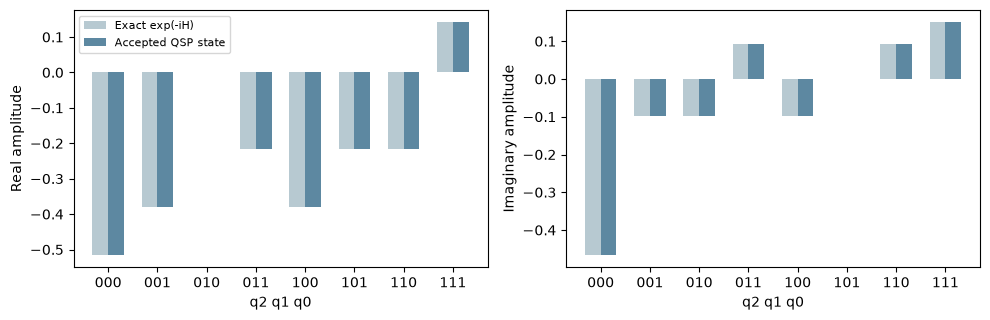

In [4]:
accepted, acceptance = qe.postselected_evolution_state(circuit, initial)
exact_state = expm(-1j*H) @ initial
labels = [f"{i:03b}" for i in range(8)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
positions = np.arange(8)
for ax, part, name in [(axes[0], np.real, "Real amplitude"), (axes[1], np.imag, "Imaginary amplitude")]:
    ax.bar(positions-.16, part(exact_state), width=.32, label="Exact exp(-iH)", color="#b7c9d1")
    ax.bar(positions+.16, part(accepted), width=.32, label="Accepted QSP state", color="#346b8a", alpha=.8)
    ax.set(xticks=positions, xticklabels=labels, xlabel="q2 q1 q0", ylabel=name)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Access, measurement and retries

The unitary generator supplies the coherent circuit. A measured trial appends final measurements on all wires; only outcomes with zero label/flag/selector bits are accepted, and the system bits supply the observable. All wires must be freshly initialized for each complete attempt. There is no amplitude amplification in this increment.

The ideal scaled-unitary acceptance is 1/16. The phase error checks and finite-H singular values are numerical evidence; neither is a formal acceptance certificate. Restart and observable-shot proposals stay conditional on their stated acceptance/synthesis assumptions. Statistical confidence and physical-fault confidence are separate.

In [5]:
compiled = hs.decompose(circuit)
measured = compiled.copy()
measured.measure_all()
counts = dict(measured.count_ops())
display(pd.DataFrame([{"operation": gate, "count per complete measured trial": count} for gate, count in counts.items()]))
print("Primitive dependency depth:", measured.depth())
print("Conditionally proposed cap for one accepted measured trial at 99% acceptance:", contract["complete_attempts_for_conditional_acceptance_projection"])
print("All phase/acceptance projections certified:", contract["certified"])

,operation,count per complete measured trial
0,cx,3770
1,rz,2063
2,t,873
3,tdg,774
4,ry,630
5,h,240
6,x,203
7,rx,186
8,measure,8
9,sdg,1


Primitive dependency depth: 6659
Conditionally proposed cap for one accepted measured trial at 99% acceptance: 72
All phase/acceptance projections certified: False


## Reproduction and limits

The source/generator records frozen cosine and sine phases and their deterministic bounded fits. The default build verifies frozen phases without launching the slower optional optimizer. A requested alpha*time inconsistent with supplied phases is rejected; other times require independently verified phases.

Dense full-Operator checks are capped at eight total wires; statevector checks at twelve. The materialized generator separately caps Pauli terms, system width, phase degree and source operations. These checks do not establish scalable black-box Hamiltonian access or a hardware speedup. Arbitrary rotation synthesis, physical error correction and deterministic/amplified evolution remain pending. The shared resource specialist must use a postselection-aware precision/workload contract.

Original MIT modules use Qiskit 2.6.2 (Apache-2.0) and SciPy 1.18.1 (BSD-3-Clause). Primary QSP/qubitization/LCU references and exact upstream attribution are on the dynamics page. No widget state or private server is required for the saved outputs.